# Desarrollo 01: el algoritmo mas basico para medir el nivel del agua

**Que es este notebook.** La carpeta `desarrollo/` documenta como evoluciona el algoritmo que mide el nivel del agua
leyendo una **mira limnimetrica** (la regla pintada que se ve en la foto): se empieza por el ejemplo mas facil con el metodo
mas simple que funcione, y cada ejemplo siguiente prueba primero ese mismo metodo sin cambios y anade solo lo que ese
ejemplo obliga a anadir. Este es el primer paso. No hace falta conocer el resto del proyecto para leerlo.

**El ejemplo.** Camara fija sobre la mira de la compuerta del rio Meguro (Tokio), en un tramo con marea. Son 53 fotos de un
directo de YouTube, una cada 5 min, del 20-oct-2026 de 12:45 a 17:00 hora de Japon. Las capturo la prueba
`05_tokio_meguro_suimon`; aqui solo se leen.

**El metodo, en una frase.** El agua es un espejo: **la linea de agua es la fila de la mira donde lo de arriba y lo de abajo son
imagen especular**. Con esa fila, pasar a nivel es una resta, porque antes se endereza la mira para que cada fila valga
siempre el mismo nivel.

**Resultado.** Sin ajustar nada, frente al nivel oficial: **error absoluto medio 1.11 cm, sesgo -0.91 cm, 92 % de las medidas en +-2 cm y 98 % en +-5 cm** (50 fotos con lectura de 53; las otras 3 quedan bajo el minimo medible). Restando el sesgo, 0.84 cm. El peor fallo es un salto de -8 cm a las 13:25, que no se filtra a proposito. No es una prueba del todo a ciegas: ver la seccion 7.

| Seccion | |
|---|---|
| 0. Preparacion | librerias, rutas y utilidades; se tapa el nivel impreso en el video |
| 1. Una foto | que se ve y por que este ejemplo es el mas facil |
| 2. Lo que no funciono | cuatro ideas mas simples, probadas sobre las 53 fotos |
| 3. Configuracion | 4 puntos y 2 niveles para enderezar la mira; marcas de control; rango de medida |
| 4. El algoritmo | paso a paso sobre una foto: ventanas, espejo, curva de parecido, pico |
| 5. De fila a nivel | la conversion |
| 6. Toda la serie | una medida por foto, sin mirar todavia el nivel oficial |
| 7. Comparacion | una sola vez, con el nivel oficial y sin ajustar nada |
| 8. Video | camara a la izquierda, mira de cerca a la derecha |
| 9. Limitaciones | que se queda sin resolver y que tendra que mejorar el siguiente ejemplo |

## 0. Preparacion

Librerias, rutas y unas utilidades. Las fotos se leen de la carpeta de la prueba 05, que no se modifica; lo que produce este
notebook va a la carpeta `salidas/` de esta prueba, con el prefijo `01_`.

**El directo lleva impreso el nivel oficial** arriba a la derecha. `leer` tapa esa franja en negro al abrir cada foto: asi el
metodo no puede verlo y el nivel oficial solo se usa en la seccion 7.

In [1]:
import os
import sys
import glob
from datetime import datetime

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Rectangle, Polygon

sys.path.insert(0, os.path.join("..", "..", "herramientas"))
import escritor_video                     # escribe H.264 por una tuberia a ffmpeg (cv2.VideoWriter no sirve aqui)

plt.rcParams.update({"figure.dpi": 90, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#8a8984", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "axes.labelcolor": "#52514e"})

# Colores de las figuras: rojo = linea de agua, azul = lo medido y las ventanas, naranja = nivel oficial
ROJO, AZUL, NARANJA, AMARILLO = "#e34948", "#2a78d6", "#eb6834", "#eda100"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"

DATOS = os.path.join("..", "..", "05_tokio_meguro_suimon", "datos")
CARPETA_FOTOS = os.path.join(DATOS, "capturas")
CSV_REFERENCIA = os.path.join(DATOS, "referencia_nivel.csv")     # solo se abre en la seccion 7
SALIDAS = "salidas"
os.makedirs(SALIDAS, exist_ok=True)

TEXTO_NIVEL = (430, 15, 960, 95)          # x0, y0, x1, y1: franja con el nivel oficial impreso


def leer(archivo):
    img = cv2.imread(os.path.join(CARPETA_FOTOS, archivo))
    x0, y0, x1, y1 = TEXTO_NIVEL
    img[y0:y1, x0:x1] = 0
    return img


def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def gris(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)


def hora_de(archivo):
    # 20261020_124454.jpg -> 2026-10-20 12:44:54 (hora de Japon en que se pidio el frame)
    return datetime.strptime(os.path.basename(archivo)[:15], "%Y%m%d_%H%M%S")


fotos = sorted(os.path.basename(f) for f in glob.glob(os.path.join(CARPETA_FOTOS, "*.jpg")))
imgs = {a: leer(a) for a in fotos}
print("%d fotos, de %s a %s" % (len(fotos), hora_de(fotos[0]), hora_de(fotos[-1])))

53 fotos, de 2026-10-20 12:44:54 a 2026-10-20 17:00:00


## 1. Una foto

La mira es una placa vertical pintada en bloques de 0.5 m, con el numero de cada bloque **al pie del bloque**. Las alturas estan
en metros sobre **A.P.** (Arakawa Peil, el cero de referencia que usa Tokio). El agua solo se mueve en el bloque de abajo, el del
"1.5", verdoso por las algas; debajo de la linea de agua se ve el reflejo de la mira.

**Por que es el ejemplo mas facil**: camara fija, mira vertical, todo de dia, y el nivel oficial esta en el mismo cero que la
mira, asi que para comparar no hay que ajustar nada.

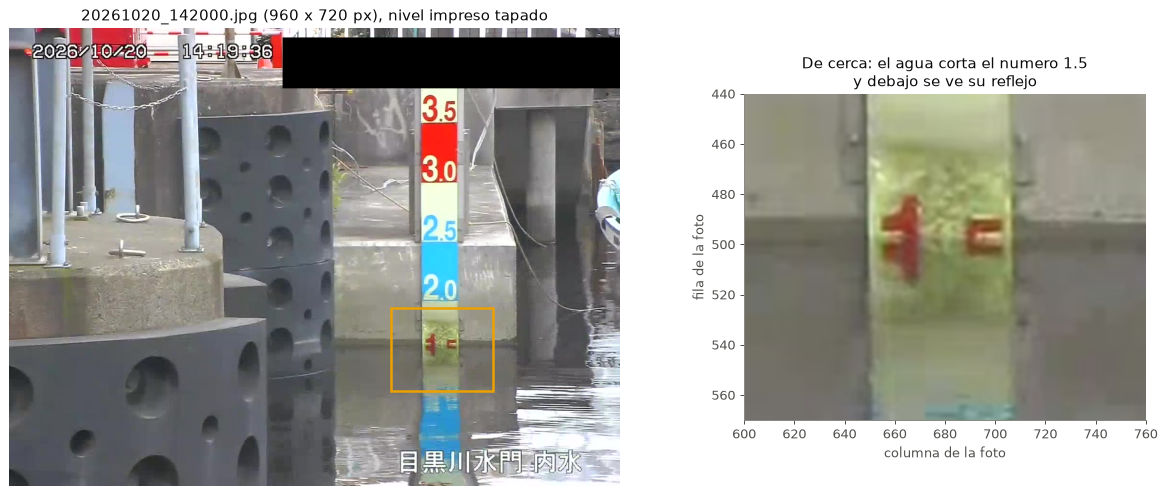

In [2]:
FOTO = "20261020_142000.jpg"            # la foto con la que se explica el metodo
img = imgs[FOTO]

fig, ax = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [2.0, 1]})
ax[0].imshow(rgb(img)); ax[0].axis("off")
ax[0].set_title("%s (%d x %d px), nivel impreso tapado" % (FOTO, img.shape[1], img.shape[0]), color=TINTA)
ax[0].add_patch(Rectangle((600, 440), 160, 130, fill=False, ec=AMARILLO, lw=2))
ax[1].imshow(rgb(img[440:570, 600:760]), extent=[600, 760, 570, 440], interpolation="bicubic")
ax[1].set_title("De cerca: el agua corta el numero 1.5\ny debajo se ve su reflejo", color=TINTA)
ax[1].set_xlabel("columna de la foto"); ax[1].set_ylabel("fila de la foto")
plt.tight_layout()